# 09 — Catalogs from the base catalog

The two-step routine in its simplest form.

1. **Step 1, once** (`romanmock base`, notebook 07): the base catalog stores every galaxy with a line above
   1.0e-16 erg/s/cm² in the grism bandpass, with positions, redshifts and the flux of all nine lines.
2. **Step 2, as often as you like**: one call, `base.make_catalog(...)`, with the flux limits, the confusion
   matrix, the lines and the redshift range of your choice. It returns the catalog in memory as numpy arrays.

Nothing is written unless you ask for it, and nothing is remembered between calls: change a setting and run the
cell again. A call takes 15–20 s on a login node.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
from romanmock import BaseCatalog

base = BaseCatalog(os.path.join(WORK, "two_step", "base"))
print(base)
print("columns a catalog can contain:", base.columns)

<BaseCatalog /pscratch/sd/w/willlake/romanmock_demo/two_step/base: 64,556,046 galaxies in 66 slices, 0.02 < z < 4.00; flux limit 1.00e-16 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312']>
columns a catalog can contain: ['gal_id', 'ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'line_bitmask', 'n_det', 'line_true', 'line_assigned', 'Ha_flux', 'Hb_flux', 'OIII_5007_flux', 'OIII_4959_flux', 'OII_3727_flux', 'SIII_9532_flux', 'SIII_9069_flux', 'OIII_4363_flux', 'SIII_6312_flux', 'line_bitmask_base']


## Make a catalog

Every argument is optional; `help(base.make_catalog)` lists them all.

In [3]:
confusion = {                                   # single-line galaxies: {true line: {assigned line: probability}}
    "Ha":        {"OIII_5007": 0.2},            # lines that are not listed are identified correctly
    "OIII_5007": {"Ha": 0.2},
    "SIII_9532": {"Ha": 0.2},
    "Hb":        {"OIII_5007": 0.2},
}

cat = base.make_catalog(
    flux_limit=1.5e-16,               # primary limit: at least one line of the galaxy above it
    secondary_flux_limit=8.0e-17,     # limit for the other lines of such a galaxy (None: no second tier)
    confusion=confusion,              # None: the package default
    lines=["Ha"],                     # galaxies whose assigned line is Ha (None: every line)
    z_range=(1.0, 1.9),               # range of redshift_assigned
    seed=2026,
)
print(cat.summary())

[romanmock] 66 slices of base, 8 worker(s)


[romanmock] 44,929,655 of 64,556,046 base galaxies detected; 23,047,548 in the catalog


<Catalog: 23,047,548 galaxies, 6 columns ['ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome']; F > 1.50e-16 (other lines > 8.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.9)>
  MULTI_LINE        18,144,770  ( 78.73%)
  SINGLE_CORRECT     4,768,942  ( 20.69%)
  SINGLE_MISID         133,836  (  0.58%)


In [4]:
from astropy.table import Table

print(type(cat["ra"]), cat["ra"].dtype, cat["ra"].shape)      # columns are numpy arrays
t = Table({c: cat[c][:8] for c in cat.columns})
for c in ("ra", "dec", "redshift_true", "redshift_rsd", "redshift_assigned"):
    t[c].format = ".5f"
t

<class 'numpy.ndarray'> float64 (23047548,)


ra,dec,redshift_true,redshift_rsd,redshift_assigned,id_outcome
float64,float64,float32,float64,float64,int8
87.84944,63.65046,2.79432,2.79433,1.89475,3
89.08058,64.09690,2.78174,2.78005,1.88385,3
89.51220,64.11320,2.79346,2.78636,1.88866,3
88.78176,64.41162,2.78031,2.78420,1.88702,3
89.89894,64.84232,2.77790,2.78331,1.88634,3
89.15748,64.84885,2.76156,2.76491,1.87230,3
88.53047,65.24188,2.76582,2.77205,1.87775,3
89.63646,65.39950,2.78666,2.78500,1.88763,3


`redshift_assigned` is the measured redshift. For a galaxy with more than one detected line it equals
`redshift_rsd` (the true redshift including the peculiar velocity), not `redshift_true`. For a single-line
galaxy it follows from the line identity drawn from the confusion matrix: equal to `redshift_rsd` when the
identification is right (`id_outcome` 2), displaced when it is wrong (`id_outcome` 3, an interloper).

In [5]:
multi, right, wrong = (cat["id_outcome"] == k for k in (1, 2, 3))
print("multi-line:        redshift_assigned == redshift_rsd for all:", np.array_equal(cat["redshift_assigned"][multi], cat["redshift_rsd"][multi]),
      "| == redshift_true for", f"{np.mean(cat['redshift_assigned'][multi] == cat['redshift_true'][multi]):.4f}")
print("single, correct:   max |redshift_assigned - redshift_rsd| =", f"{np.abs(cat['redshift_assigned'][right] - cat['redshift_rsd'][right]).max():.1e}")
print("single, interloper: true redshifts", f"{cat['redshift_rsd'][wrong].min():.2f}-{cat['redshift_rsd'][wrong].max():.2f}",
      "assigned", f"{cat['redshift_assigned'][wrong].min():.2f}-{cat['redshift_assigned'][wrong].max():.2f}")

multi-line:        redshift_assigned == redshift_rsd for all: True | == redshift_true for 0.0000


single, correct:   max |redshift_assigned - redshift_rsd| = 4.4e-16
single, interloper: true redshifts 0.38-2.80 assigned 1.00-1.90


## Change anything and run again

Each call is independent. Here the same selection for three confusion matrices and two pairs of flux limits.

In [6]:
import time

rows = []
for label, conf in [("package default", None), ("20 % (the matrix above)", confusion), ("perfect identification", {})]:
    for primary, secondary in [(1.0e-16, 4.0e-17), (1.5e-16, 8.0e-17)]:
        t0 = time.time()
        c = base.make_catalog(flux_limit=primary, secondary_flux_limit=secondary, confusion=conf, lines=["Ha"],
                              z_range=(1.0, 1.9), seed=2026, verbose=False)
        o = c.outcomes()
        rows.append({"confusion": label, "primary": f"{primary:.1e}", "secondary": f"{secondary:.1e}", "galaxies": len(c),
                     "multi-line %": round(100 * o["MULTI_LINE"] / len(c), 2),
                     "interlopers %": round(100 * o["SINGLE_MISID"] / len(c), 3), "seconds": round(time.time() - t0)})
Table(rows)

confusion,primary,secondary,galaxies,multi-line %,interlopers %,seconds
str23,str7,str7,int64,float64,float64,int64
package default,1.0e-16,4.0e-17,36900980,91.99,0.002,19
package default,1.5e-16,8.0e-17,24110398,75.26,0.137,22
20 % (the matrix above),1.0e-16,4.0e-17,36323975,93.45,0.009,20
20 % (the matrix above),1.5e-16,8.0e-17,23047548,78.73,0.581,21
perfect identification,1.0e-16,4.0e-17,36915031,91.95,0.0,22
perfect identification,1.5e-16,8.0e-17,24107025,75.27,0.0,20


Other cuts work the same way: `z_column="redshift_true"` to cut on another redshift, `n_det_min=2` for
multi-line galaxies only, `outcomes=None` to keep galaxies without a redshift, `cuts={"dec": (60, 70)}` on any
column, and `columns=[...]` or `columns="all"` (line fluxes, bitmask, `gal_id`, ...) for what is returned.

In [7]:
o3 = base.make_catalog(flux_limit=1.0e-16, lines=["OIII_5007"], z_range=(2.0, 2.9), cuts={"dec": (60.0, 70.0)},
                       columns=["gal_id", "ra", "dec", "redshift_assigned", "id_outcome", "n_det", "line_bitmask",
                                "OIII_5007_flux", "Hb_flux"], seed=2026, verbose=False)
print(o3)
print("median [O III] 5007 flux:", f"{np.median(o3['OIII_5007_flux']):.2e}", "erg/s/cm²; detected lines per galaxy:",
      {int(k): int(v) for k, v in zip(*np.unique(o3["n_det"], return_counts=True))})

<Catalog: 1,708,094 galaxies, 9 columns ['gal_id', 'ra', 'dec', 'redshift_assigned', 'id_outcome', 'n_det', 'line_bitmask', 'OIII_5007_flux', 'Hb_flux']; F > 1.00e-16 (other lines > 4.00e-17); lines ['OIII_5007'], redshift_assigned in (2.0, 2.9)>
median [O III] 5007 flux: 1.28e-16 erg/s/cm²; detected lines per galaxy: {1: 7551, 2: 510700, 3: 393698, 4: 796144, 5: 1}


## Downsampling to the Wang et al. (2022) forecast

Off by default. `downsample="wang2022"` thins the Hα and [O III] emitter populations to the forecast at the
primary flux limit, in bins of true redshift, before the cuts are applied (so interlopers are thinned with the
population they belong to). The flux limit must be one of the tabulated ones (5e-17, 7e-17, 8.5e-17, 1e-16,
1.5e-16, 2e-16). `downsample={"reference": "wang2022", "dust_av": 1.92}` selects the other dust model.

/tmp/ipykernel_645202/1014149642.py:6: RuntimeWarning: target dN/dz exceeds the mock in 2 of 15 bins (z ~ 0.55-0.65); thinning cannot fill a shortage, those bins keep every galaxy.
  thin = base.make_catalog(downsample="wang2022", **kw)        # warns where the mock has fewer emitters than the forecast


/tmp/ipykernel_645202/1014149642.py:6: RuntimeWarning: OIII_5007: 10 of 20 target bins (z 1.00-3.00) contain no galaxies whose brightest line is OIII_5007; the target cannot be applied there.
  thin = base.make_catalog(downsample="wang2022", **kw)        # warns where the mock has fewer emitters than the forecast
/tmp/ipykernel_645202/1014149642.py:6: RuntimeWarning: target dN/dz exceeds the mock in 1 of 20 bins (z ~ 2.85-2.85); thinning cannot fill a shortage, those bins keep every galaxy.
  thin = base.make_catalog(downsample="wang2022", **kw)        # warns where the mock has fewer emitters than the forecast


<Catalog: 7,835,755 galaxies, 6 columns ['ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome']; F > 1.50e-16 (other lines > 8.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.9), downsampled to {'reference': 'wang2022'}>
  MULTI_LINE         6,241,355  ( 79.65%)
  SINGLE_CORRECT     1,495,068  ( 19.08%)
  SINGLE_MISID          99,332  (  1.27%)
  population Ha: 39,057,136 -> 19,359,009 emitters (p_keep 0.110-1.000)
  population OIII_5007: 986,033 -> 560,233 emitters (p_keep 0.000-1.000)


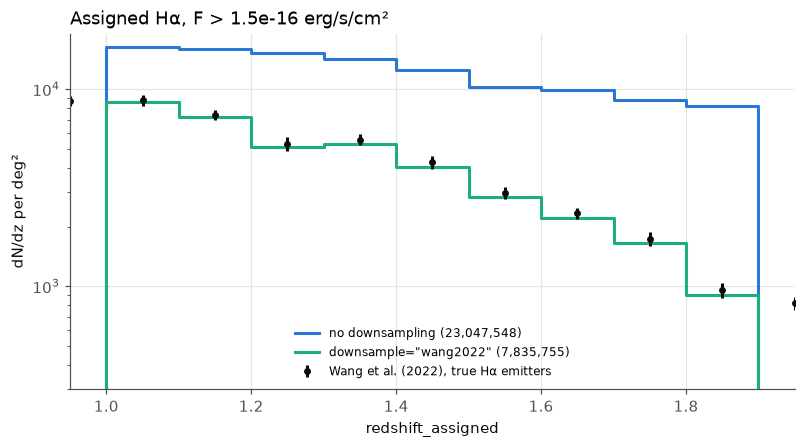

In [8]:
from romanmock.reference_dndz import wang2022_bins, wang2022_errors

kw = dict(flux_limit=1.5e-16, secondary_flux_limit=8.0e-17, confusion=confusion, lines=["Ha"], z_range=(1.0, 1.9),
          seed=2026, verbose=False)
full = base.make_catalog(**kw)
thin = base.make_catalog(downsample="wang2022", **kw)        # warns where the mock has fewer emitters than the forecast
print(thin.summary())

edges, ref = wang2022_bins("Ha", 1.5e-16)
err = wang2022_errors("Ha", 1.5e-16)
zc = 0.5 * (edges[1:] + edges[:-1])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.step(zc, full.dndz(edges), where="mid", color=plotting.CATEGORICAL[0], label=f"no downsampling ({len(full):,})")
ax.step(zc, thin.dndz(edges), where="mid", color=plotting.CATEGORICAL[2], label=f'downsample="wang2022" ({len(thin):,})')
ax.errorbar(zc, ref, yerr=err, fmt="o", ms=3.5, color=plotting.TEXT_PRIMARY, label="Wang et al. (2022), true Hα emitters")
ax.set_xlim(0.95, 1.95); ax.set_yscale("log"); ax.set_ylim(300, None)
ax.set_xlabel("redshift_assigned"); ax.set_ylabel("dN/dz per deg²")
ax.set_title("Assigned Hα, F > 1.5e-16 erg/s/cm²"); ax.legend(fontsize=8); plt.show()

## Writing to disk

`cat.write(path)` writes `.hdf5` (one dataset per column, the settings in the file attributes), `.fits` or
`.npz`, replacing an existing file. `make_catalog(..., write_to=path)` does both in one call, and
`Catalog.read(path)` brings a catalog back with its settings.

In [9]:
from romanmock import Catalog

path = thin.write(os.path.join(WORK, "two_step", "halpha_z1p0_1p9.hdf5"))
print(path, f"{os.path.getsize(path) / 1e9:.2f} GB")
back = Catalog.read(path)
print(back)
print({k: back.settings[k] for k in ("flux_limit", "secondary_flux_limit", "lines", "z_range", "downsample", "seed")})

/pscratch/sd/w/willlake/romanmock_demo/two_step/halpha_z1p0_1p9.hdf5 0.29 GB
<Catalog: 7,835,755 galaxies, 6 columns ['ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome']; F > 1.50e-16 (other lines > 8.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.9), downsampled to {'reference': 'wang2022'}>
{'flux_limit': 1.5e-16, 'secondary_flux_limit': 8e-17, 'lines': ['Ha'], 'z_range': [1.0, 1.9], 'downsample': {'reference': 'wang2022'}, 'seed': 2026}


## From the command line

```bash
romanmock catalog $PSCRATCH/romanmock_demo/two_step/base -o halpha.hdf5 \
          --flux-limit 1.5e-16 --secondary-flux-limit 8e-17 --confusion my_confusion.yaml \
          --lines Ha --z-range 1.0 1.9 --downsample wang2022
```

`my_confusion.yaml` holds the rows, e.g. `Ha: {OIII_5007: 0.2}`. Inside a script, call `make_catalog` below
`if __name__ == "__main__":` because the slices are read by worker processes.